In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

In [2]:
DATA_PATH = Path("../data/processed/transactions_12w.parquet")

transactions = pd.read_parquet(DATA_PATH)

print("Shape:", transactions.shape)
print("\nColumns:")
print(transactions.columns.tolist())

display(transactions.head())


Shape: (3386963, 5)

Columns:
['t_dat', 'customer_join_idx', 'article_id', 'price', 'sales_channel_id']


,t_dat,customer_join_idx,article_id,price,sales_channel_id
0,2020-07-01,38,825577003,0.013542,2
1,2020-07-01,38,849487005,0.042356,2
2,2020-07-01,38,772659001,0.023712,2
3,2020-07-01,38,804732004,0.042356,2
4,2020-07-01,38,804732004,0.042356,2


In [3]:
customer_count = (transactions.groupby('customer_join_idx').size().rename('purchase_count'))

In [4]:
customer_percentiles = customer_count.quantile([0.5, 0.9, 0.95, 0.99])

In [5]:
summary = pd.DataFrame({
    "Percentile": ["50th", "90th", "95th", "99th", "Maximum"],
    "purchase_count": [
        customer_percentiles.loc[0.5],
        customer_percentiles.loc[0.9],
        customer_percentiles.loc[0.95],
        customer_percentiles.loc[0.99],
        customer_count.max(),
    ],
})

In [6]:
article_count = (transactions.groupby('article_id').size().rename('purchase_count'))
article_percentile = article_count.quantile([0.5,0.9,0.95,0.99])

summary_article =pd.DataFrame({
    "Percentile": ["50th", "90th","95th","99th", "Maximum"],
    "purchase_count": [
        article_percentile.loc[0.5],
        article_percentile.loc[0.9],
        article_percentile.loc[0.95],
        article_percentile.loc[0.99],
        article_count.max(),
    ],
})

In [7]:
print("Customers:")
print(summary)
print("Articles:")
print(summary_article)

Customers:
  Percentile  purchase_count
0       50th             4.0
1       90th            15.0
2       95th            21.0
3       99th            39.0
4    Maximum           316.0
Articles:
  Percentile  purchase_count
0       50th           12.00
1       90th          226.00
2       95th          412.00
3       99th          969.58
4    Maximum         5673.00


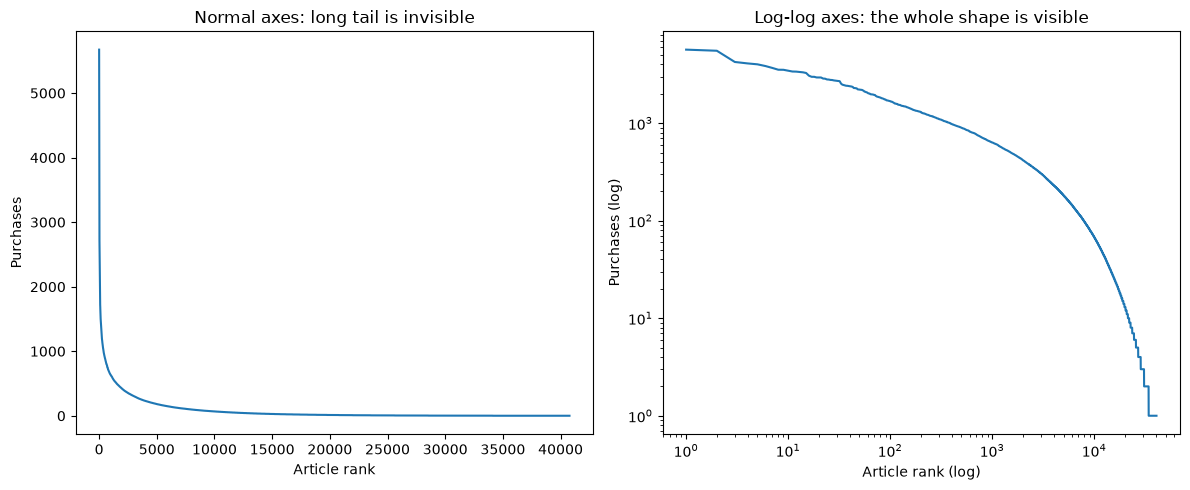

In [8]:
# Log-log popularity plot: article rank vs purchase count
import matplotlib.pyplot as plt

article_sorted = article_count.sort_values(ascending=False)   # best seller first
ranks = range(1, len(article_sorted) + 1)                       # 1, 2, 3, ...

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)                       # left: normal axes
plt.plot(ranks, article_sorted.values)
plt.title('Normal axes: long tail is invisible')
plt.xlabel('Article rank')
plt.ylabel('Purchases')

plt.subplot(1, 2, 2)                       # right: log-log axes
plt.plot(ranks, article_sorted.values)
plt.xscale('log')
plt.yscale('log')
plt.title('Log-log axes: the whole shape is visible')
plt.xlabel('Article rank (log)')
plt.ylabel('Purchases (log)')

plt.tight_layout()
plt.savefig(r'C:/Users/srisu/AppData/Local/Temp/claude/5f3aba0acd41fd42/ed8e8adb-1872-4f2c-9715-dac9ee828a10/scratchpad/loglog.png')
plt.show()

In [9]:
#Calculate Sparsity
n_customers = transactions['customer_join_idx'].nunique()
n_articles = transactions['article_id'].nunique()

n_interactions = len(
    transactions[['customer_join_idx', 'article_id']].drop_duplicates()
)

total_possible_interactions = n_customers * n_articles

sparsity = 1 - (n_interactions / total_possible_interactions)

print(f"Sparsity of the dataset: {sparsity:.6f}")
print(f"Number of unique customers: {n_customers}")
print(f"Number of unique articles: {n_articles}")
print(f"Number of unique interactions: {n_interactions}")
print(f'Matrix Density: {1-sparsity:.6f}')

Sparsity of the dataset: 0.999850
Number of unique customers: 489553
Number of unique articles: 40772
Number of unique interactions: 2992254
Matrix Density: 0.000150


In [10]:
# Top 1%
top_n = int(len(article_sorted) * 0.01)
top_sales = article_sorted.head(top_n).sum()
top_share = top_sales / article_sorted.sum()
print(f"Top 1% of articles ({top_n} articles) = {top_share:.1%} of all purchases")

Top 1% of articles (407 articles) = 18.3% of all purchases


In [11]:
# Same-day duplicates
is_duplicate = transactions.duplicated(subset=['t_dat', 'customer_join_idx', 'article_id'])

print("Duplicate rows:", is_duplicate.sum())
print(f"Duplicate fraction: {is_duplicate.mean():.2%}")

Duplicate rows: 301088
Duplicate fraction: 8.89%


In [37]:
# Remove same-day copies (~ means NOT, so keep rows that are NOT duplicates)
cleaned = transactions[~is_duplicate]

In [38]:
# For each customer + article pair: on how many different days was it bought?
days_per_pair = cleaned.groupby(['customer_join_idx', 'article_id']).size()

In [39]:
# Fraction of pairs bought on more than one day
repeat_rate = (days_per_pair > 1).mean()
print(f"Repeat rate: {repeat_rate:.2%} of customer-article pairs were bought again on a different day")

Repeat rate: 2.95% of customer-article pairs were bought again on a different day
